# Seebeck features: extract, explore, preprocess

**Input:** `matched_points.csv` from the dataset notebook (or the whole `seebeck_dataset.zip`).

**Steps**
1. Load the data and fix two gaps: valence electrons for lanthanides and actinides, and SPB values at extreme n or T
2. Save the 6 chosen inputs plus the target to a separate file → `seebeck_features_raw.csv`
3. Explore: ranges, percentiles, distributions, correlations
4. Preprocess: physical limits, duplicates reused across papers, outliers, near-zero S, optional thinning
5. Save → `seebeck_features_clean.csv`, `removed_rows.csv` (with the reason for each removal), `preprocessing_report.json`

| Input | Meaning |
|---|---|
| `T_K` | temperature (K) |
| `log10_n_cm3` | log₁₀ carrier concentration (cm⁻³) |
| `S_SPB_abs_m1_uVK` | SPB baseline \|S\| from n and T only (m* = 1 mₑ, acoustic phonon scattering) |
| `el_X_mean` | fraction-weighted mean Pauling electronegativity |
| `el_n_valence_mean` | fraction-weighted mean valence electrons |
| `dopant_total_frac` | total atomic fraction of elements below 5 at.% |

Targets are saved as `S_uVK` (signed), `S_abs_uVK` and the SPB residual `dS_uVK` = \|S\| − S_SPB.

## 0. Settings

In [1]:
INPUT = "matched_points.csv"      # or "seebeck_dataset.zip"; if missing you'll be asked to upload
OUT_DIR = "seebeck_features"

# basic row filters (from the dataset notebook's flags)
DROP_FLAGS = ["flag_not_experiment", "flag_not_bulk", "flag_S_range", "flag_n_range", "flag_T_range"]
EXCLUDE_SIGN_CHANGING = True      # bipolar samples (S changes sign): single-band SPB does not apply

# physical limits (rows outside are removed)
LIMITS = {
    "T_K":              (10, 1300),     # K
    "log10_n_cm3":      (17, 22.5),     # 1e17 to 3e22 cm^-3
    "S_abs_uVK":        (0, 1000),      # uV/K
    "el_X_mean":        (0.7, 4.0),
    "el_n_valence_mean":(0, 12),
    "dopant_total_frac":(0, 0.25),
}
MIN_ABS_S = 5.0          # |S| below this (uV/K) is dropped: near zero crossings, relative errors blow up
ROBUST_Z = 5.0           # MAD z-score cutoff for feature outliers (per variable)
RESIDUAL_OUTLIERS = False  # also drop rows whose SPB residual is extreme (uses the target -> sensitivity check only)
DEDUP_ACROSS_PAPERS = True # same composition + T + n + S in different papers = reused data -> keep one
MAX_POINTS_PER_SAMPLE = None  # e.g. 15 to thin dense curves (useful for PySR); None = keep all

FEATURES = ["T_K", "log10_n_cm3", "S_SPB_abs_m1_uVK", "el_X_mean", "el_n_valence_mean", "dopant_total_frac"]
TARGETS = ["S_uVK", "S_abs_uVK", "dS_uVK"]
KEEP = ["point_id", "study_id", "sample_key", "SID", "DOI", "sample_name", "composition",
        "comp_system", "carrier_type", "carrier_type_confidence", "n_source", "dT_K", "S_figure_id"]

In [2]:
import json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
OUT = Path(OUT_DIR); OUT.mkdir(exist_ok=True)

## 1. Load

In [3]:
p = Path(INPUT)
if not p.exists():
    try:
        from google.colab import files
        up = files.upload()                      # choose matched_points.csv or seebeck_dataset.zip
        p = Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError(INPUT)
if p.suffix == ".zip":
    with zipfile.ZipFile(p) as z:
        z.extract("matched_points.csv", ".")
    p = Path("matched_points.csv")
m = pd.read_csv(p, low_memory=False)
print(m.shape)

Saving seebeck_dataset.zip to seebeck_dataset.zip
(17670, 183)


## 2. Fix valence electrons (lanthanides and actinides)
pymatgen leaves f-block elements undefined, so `el_n_valence_mean` was missing for about 14% of points.
It's recomputed here for **every** row from one explicit table, so all rows use the same convention:
- s/p block: group number (group ≥ 13 → group − 10)
- d block: group number
- f block: usual valence in compounds (most lanthanides 3; Eu, Yb 2; Th 4; U 6)

Compositions containing symbols that aren't real elements (Starrydata typos such as "Ze", "Zb") are removed.

In [4]:
VALENCE = {
 "H":1,"Li":1,"Be":2,"B":3,"C":4,"N":5,"O":6,"F":7,
 "Na":1,"Mg":2,"Al":3,"Si":4,"P":5,"S":6,"Cl":7,
 "K":1,"Ca":2,"Sc":3,"Ti":4,"V":5,"Cr":6,"Mn":7,"Fe":8,"Co":9,"Ni":10,"Cu":11,"Zn":12,
 "Ga":3,"Ge":4,"As":5,"Se":6,"Br":7,
 "Rb":1,"Sr":2,"Y":3,"Zr":4,"Nb":5,"Mo":6,"Tc":7,"Ru":8,"Rh":9,"Pd":10,"Ag":11,"Cd":12,
 "In":3,"Sn":4,"Sb":5,"Te":6,"I":7,
 "Cs":1,"Ba":2,"Hf":4,"Ta":5,"W":6,"Re":7,"Os":8,"Ir":9,"Pt":10,"Au":11,"Hg":12,
 "Tl":3,"Pb":4,"Bi":5,"Po":6,"At":7,
 # f block (convention: common valence in compounds)
 "La":3,"Ce":3,"Pr":3,"Nd":3,"Pm":3,"Sm":3,"Eu":2,"Gd":3,"Tb":3,"Dy":3,"Ho":3,"Er":3,"Tm":3,"Yb":2,"Lu":3,
 "Ac":3,"Th":4,"Pa":5,"U":6,"Np":5,"Pu":4,
}
F_BLOCK = {"La","Ce","Pr","Nd","Pm","Sm","Eu","Gd","Tb","Dy","Ho","Er","Tm","Yb","Lu","Ac","Th","Pa","U","Np","Pu"}

def valence_mean(js):
    if not isinstance(js, str):
        return np.nan, False
    f = json.loads(js)
    if any(e not in VALENCE for e in f):
        return np.nan, False
    return sum(v * VALENCE[e] for e, v in f.items()), True

vals = m["elem_frac_json"].map(valence_mean)
new_val = vals.map(lambda t: t[0]); known = vals.map(lambda t: t[1])
# sanity check: must agree with pymatgen wherever pymatgen had a value
m["has_f_block"] = m["elem_frac_json"].map(lambda js: isinstance(js, str) and bool(F_BLOCK & set(json.loads(js))))
both = m["el_n_valence_mean"].notna() & new_val.notna() & ~m["has_f_block"]
print("max |difference| vs pymatgen on rows without f-block elements (should be ~0):",
      float((m.loc[both, "el_n_valence_mean"] - new_val[both]).abs().max()))
m["el_n_valence_mean"] = new_val
print("rows with unknown element symbols (removed):", int((~known & m["elem_frac_json"].notna()).sum()),
      m.loc[~known & m["elem_frac_json"].notna(), "composition"].unique()[:10])
m = m[known].copy()

max |difference| vs pymatgen on rows without f-block elements (should be ~0): 3.552713678800501e-15
rows with unknown element symbols (removed): 22 ['Ca5Al1.9Zb0.1Sb6' 'Cu2Ze0.9Fe0.1GeSe4' 'SnCd0.03Te(ZdS)0.02']


## 3. Recompute the SPB baseline over the full range
Same model as before (single parabolic band, acoustic phonon scattering, Hall factor 1, m* = 1 mₑ), but the
degenerate (η > 100) and non-degenerate (η < −30) limits are now handled analytically instead of left as NaN:
- degenerate: F½ ≈ ⅔η^{3/2}(1 + π²/8η²), \|S\| ≈ (k/e)·π²/(3η)
- non-degenerate: F½ ≈ (√π/2)eᶯ, \|S\| = (k/e)(2 − η)

In [5]:
from scipy.integrate import quad
from scipy.special import expit
KB, H_PL, M_E, E_CH = 1.380649e-23, 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19
_eta = np.linspace(-30, 100, 2601)
_F = lambda j, e: quad(lambda x: x**j * expit(e - x), 0, max(e, 0) + 60, limit=200)[0]
_F12 = np.array([_F(0.5, e) for e in _eta]); _F1 = np.array([_F(1.0, e) for e in _eta]); _F0 = np.logaddexp(0, _eta)

def spb_seebeck_abs(n_m3, T_K, m_star=1.0):
    """|S_SPB| in V/K and reduced Fermi level eta, from n (m^-3) and T (K) only."""
    n_m3, T_K = np.asarray(n_m3, float), np.asarray(T_K, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        F12 = n_m3 / (4 * np.pi * (2 * m_star * M_E * KB * T_K / H_PL**2) ** 1.5)
        eta = np.interp(np.log(F12), np.log(_F12), _eta, left=np.nan, right=np.nan)
        lo = F12 < _F12[0]; hi = F12 > _F12[-1]
        eta = np.where(lo, np.log(F12 * 2 / np.sqrt(np.pi)), eta)
        e_hi = (1.5 * F12) ** (2 / 3)                    # leading order, then one Newton-style correction
        e_hi = (1.5 * F12 / (1 + np.pi**2 / (8 * e_hi**2))) ** (2 / 3)
        eta = np.where(hi, e_hi, eta)
        S = np.where(lo, 2 - eta,
            np.where(hi, np.pi**2 / (3 * eta),
                     2 * np.interp(eta, _eta, _F1) / np.interp(eta, _eta, _F0) - eta))
    return S * KB / E_CH, eta

old = m["S_SPB_abs_m1_uVK"].copy()
S_spb, eta = spb_seebeck_abs(m["n_m3"], m["T_K"])
m["S_SPB_abs_m1_uVK"] = S_spb * 1e6; m["eta_SPB_m1"] = eta
both = old.notna() & m["S_SPB_abs_m1_uVK"].notna()
print("max |difference| vs previous SPB where both exist (uV/K):", float((old[both] - m.loc[both, "S_SPB_abs_m1_uVK"]).abs().max()))
print("SPB missing before:", int(old.isna().sum()), "| after:", int(m["S_SPB_abs_m1_uVK"].isna().sum()))

max |difference| vs previous SPB where both exist (uV/K): 0.0005354241515869163
SPB missing before: 1940 | after: 0


## 4. Build the feature file

In [6]:
m["S_abs_uVK"] = m["S_uVK"].abs()
m["dS_uVK"] = m["S_abs_uVK"] - m["S_SPB_abs_m1_uVK"]
log = {"start_rows": len(m)}
f = m[~m[DROP_FLAGS].any(axis=1)]
log["after_basic_flags"] = len(f)
f = f.dropna(subset=FEATURES + ["S_uVK"])
log["after_complete_features"] = len(f)
feat = f[KEEP + FEATURES + TARGETS + ["has_f_block", "eta_SPB_m1"]].reset_index(drop=True)
feat.to_csv(OUT / "seebeck_features_raw.csv", index=False)
print(log); print(f"saved {OUT/'seebeck_features_raw.csv'}: {len(feat)} rows, "
                  f"{feat.sample_key.nunique()} samples, {feat.SID.nunique()} papers")

{'start_rows': 17590, 'after_basic_flags': 10341, 'after_complete_features': 10341}
saved seebeck_features/seebeck_features_raw.csv: 10341 rows, 1048 samples, 291 papers


## 5. Explore: ranges and distributions

In [7]:
cols = FEATURES + ["S_uVK", "S_abs_uVK", "dS_uVK"]
desc = feat[cols].describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).T
display(desc.round(3))
print("rows per carrier type:"); display(feat.groupby("carrier_type").agg(points=("point_id", "size"),
        samples=("sample_key", "nunique"), papers=("SID", "nunique")))

,count,mean,std,min,0.1%,1%,5%,25%,50%,75%,95%,99%,99.9%,max
T_K,10341.0,296.804,204.241,2.011,2.410,4.963,15.462,124.369,296.299,425.296,671.819,798.526,1015.249,1251.452
log10_n_cm3,10341.0,19.688,1.277,16.006,16.059,16.324,17.422,18.988,19.656,20.460,21.775,22.457,22.968,22.995
S_SPB_abs_m1_uVK,10341.0,173.613,177.680,0.014,0.038,0.173,1.004,23.918,133.140,258.024,564.607,764.733,873.453,904.740
el_X_mean,10341.0,2.054,0.242,1.447,1.447,1.503,1.633,1.969,2.045,2.150,2.551,2.760,2.852,2.940
el_n_valence_mean,10341.0,5.894,1.252,2.621,2.637,3.000,4.286,5.067,5.600,6.293,9.000,9.333,9.750,10.500
dopant_total_frac,10341.0,0.008,0.014,0.000,0.000,0.000,0.000,0.000,0.000,0.010,0.038,0.056,0.079,0.100
S_uVK,10341.0,20.583,234.419,-1490.622,-1396.758,-614.104,-305.000,-99.870,15.372,145.470,359.155,649.127,1409.485,1450.655
S_abs_uVK,10341.0,159.881,172.661,0.000,0.000,0.000,1.728,52.509,121.043,210.090,444.156,877.679,1437.390,1490.622
dS_uVK,10341.0,-13.732,160.773,-723.787,-693.647,-507.135,-236.082,-67.656,1.990,34.077,156.313,623.918,1052.876,1264.606


rows per carrier type:


,points,samples,papers
carrier_type,,,
n,747,34,15
p,2043,144,54
sign-changing,765,27,17
unknown,6786,843,212


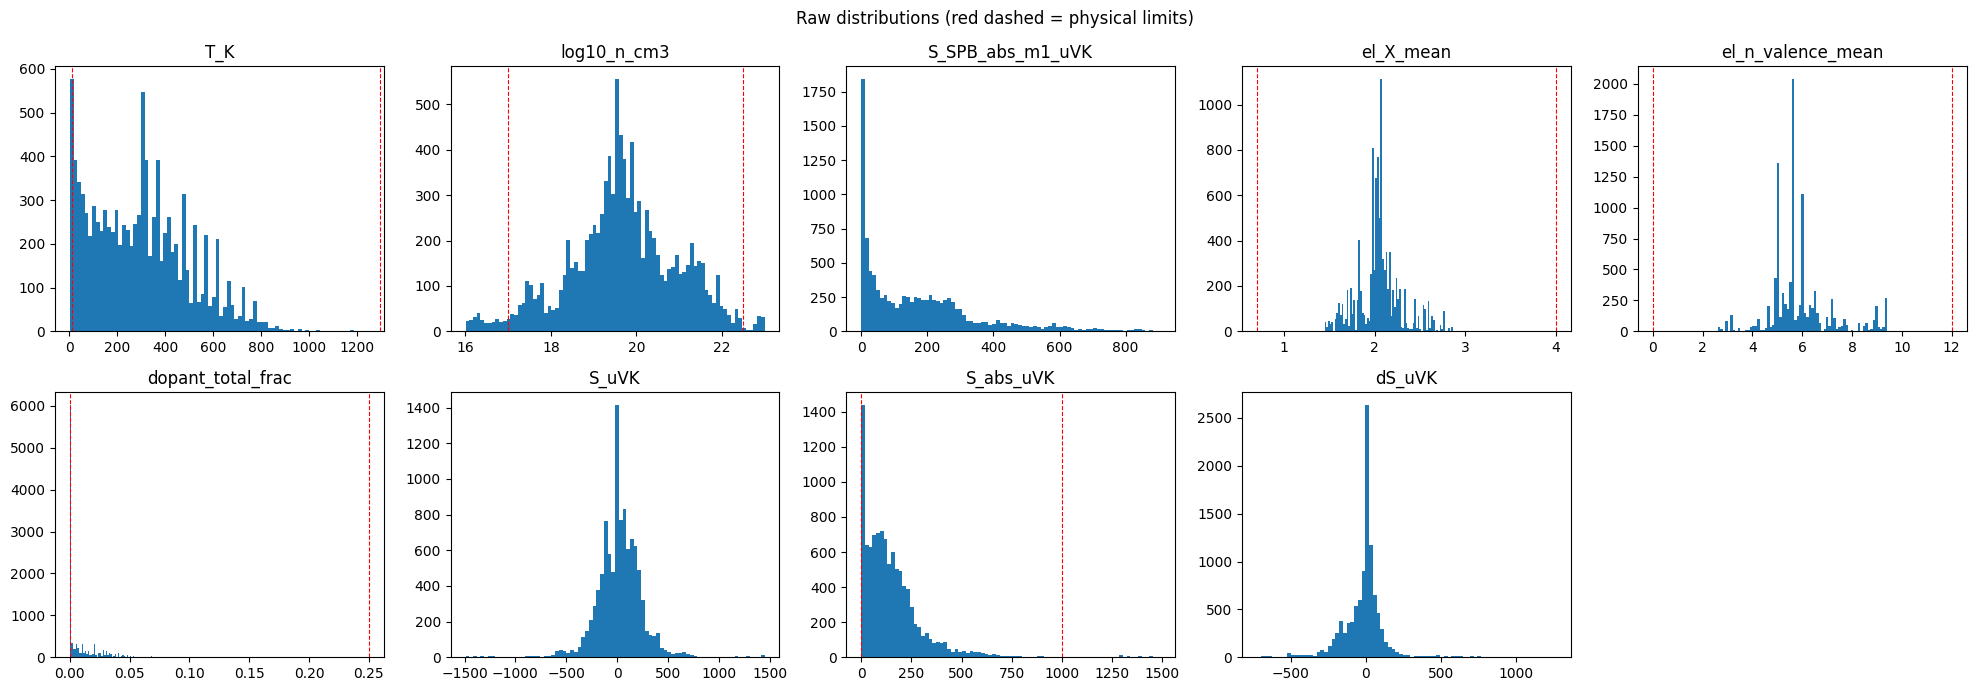

In [8]:
def hist_grid(df, cols, title, color="C0"):
    fig, ax = plt.subplots(2, 5, figsize=(20, 7)); ax = ax.ravel()
    for a, c in zip(ax, cols):
        a.hist(df[c].dropna(), bins=80, color=color); a.set_title(c)
        if c in LIMITS:
            for v in LIMITS[c]: a.axvline(v, c="r", ls="--", lw=.8)
    for a in ax[len(cols):]: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()
hist_grid(feat, cols, "Raw distributions (red dashed = physical limits)")

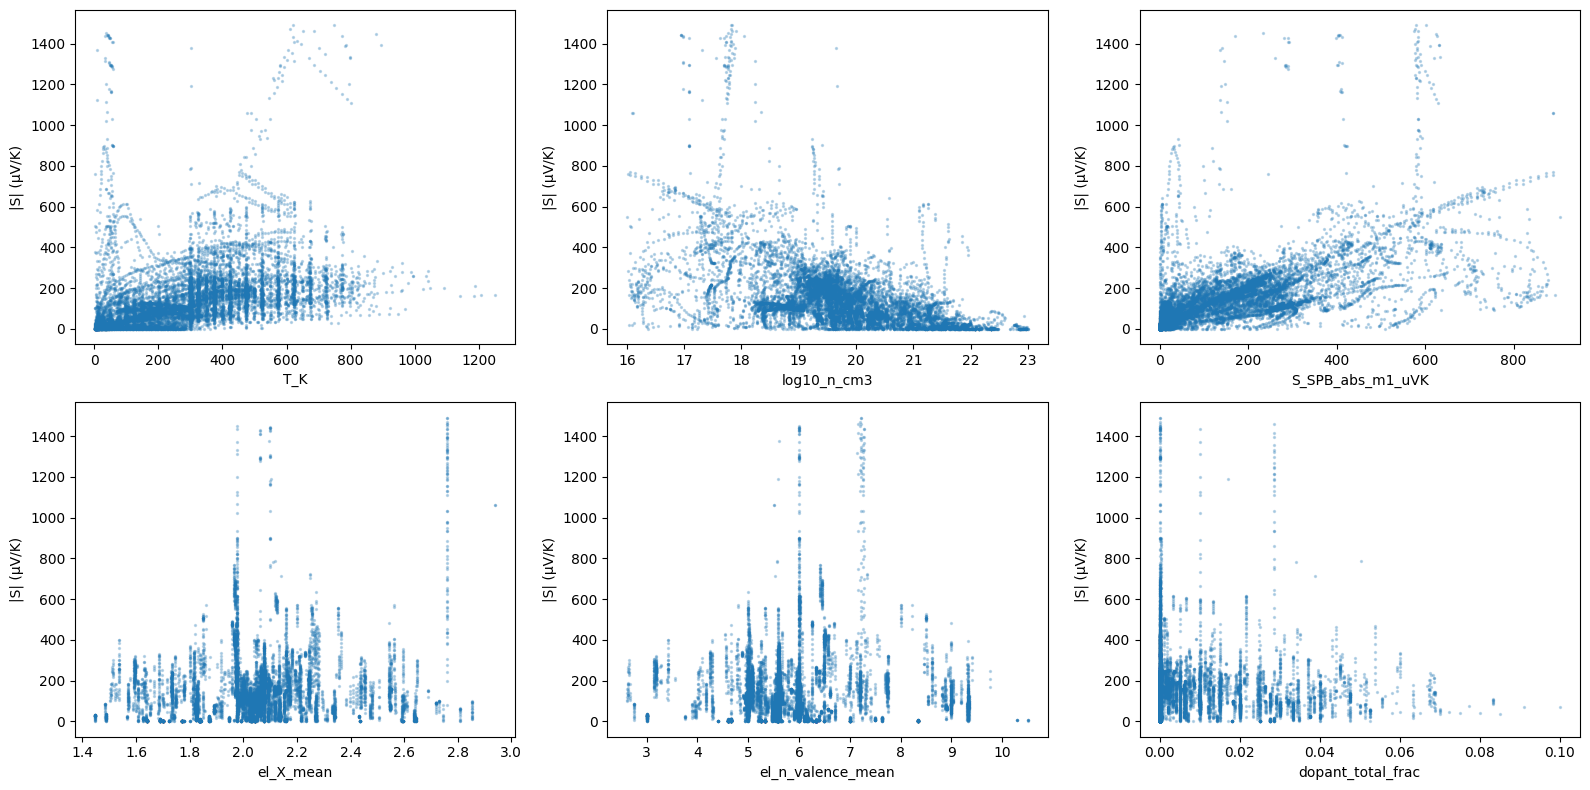

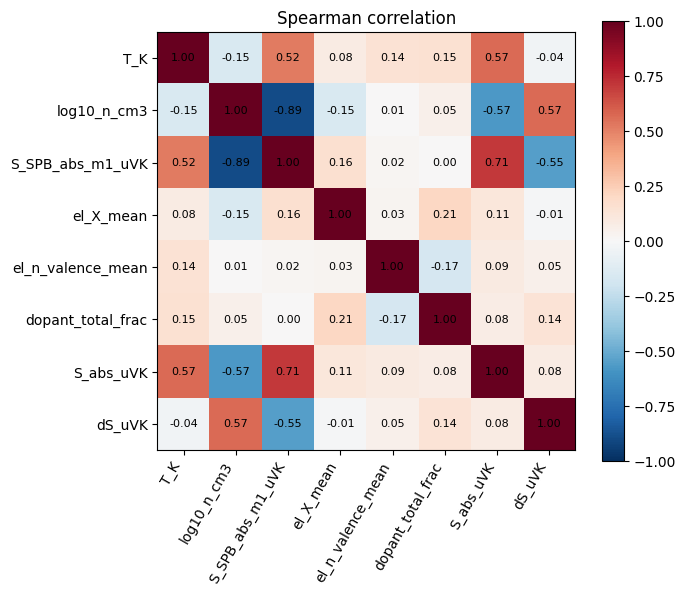

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8)); ax = ax.ravel()
for a, c in zip(ax, FEATURES):
    a.scatter(feat[c], feat["S_abs_uVK"], s=2, alpha=.25); a.set(xlabel=c, ylabel="|S| (µV/K)")
plt.tight_layout(); plt.show()
corr = feat[FEATURES + ["S_abs_uVK", "dS_uVK"]].corr(method="spearman")
plt.figure(figsize=(7, 6)); plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Spearman correlation"); plt.tight_layout(); plt.show()

## 6. Preprocess
Every removed row is kept in `removed_rows.csv` with the reason, applied in the order below.

- **Carrier type:** sign-changing samples are excluded (optional).
- **Physical limits:** the `LIMITS` values in Settings.
- **Near-zero S:** \|S\| < `MIN_ABS_S`.
- **Duplicates:** the same composition, T, n and S appearing in different papers means reused data; one copy is kept.
- **Feature outliers:** robust z = 0.6745·(x − median)/MAD > `ROBUST_Z` for any input variable. This uses inputs only.
- **Residual outliers (optional, off by default):** uses the target, so treat it as a sensitivity check and don't make it the main result.
- **Thinning (optional):** keeps at most `MAX_POINTS_PER_SAMPLE` points per sample, evenly spaced in T.

Scaling and normalisation are **not** done here. Do them inside the model pipeline, fitted on training folds only.
PySR doesn't need scaling.

In [10]:
d = feat.copy()
d["remove_reason"] = ""
def mark(mask, reason):
    new = mask & d["remove_reason"].eq("")
    d.loc[new, "remove_reason"] = reason
    return int(new.sum())
steps = {}
if EXCLUDE_SIGN_CHANGING:
    steps["sign_changing_sample"] = mark(d["carrier_type"].eq("sign-changing"), "sign_changing_sample")
for c, (lo, hi) in LIMITS.items():
    steps[f"limit_{c}"] = mark(~d[c].between(lo, hi), f"limit_{c}")
steps["near_zero_S"] = mark(d["S_abs_uVK"] < MIN_ABS_S, "near_zero_S")
if DEDUP_ACROSS_PAPERS:
    key = pd.DataFrame({"comp": d["composition"], "Tr": d["T_K"].round(0), "nr": d["log10_n_cm3"].round(2),
                        "Sr": d["S_uVK"].round(0)})
    dup = key.duplicated(keep="first") & d["remove_reason"].eq("")
    # only count as reuse if the duplicate comes from a DIFFERENT paper
    first_sid = d.groupby([key.comp, key.Tr, key.nr, key.Sr])["SID"].transform("first")
    steps["duplicate_across_papers"] = mark(dup & (d["SID"] != first_sid), "duplicate_across_papers")
alive = d["remove_reason"].eq("")
for c in FEATURES:
    x = d.loc[alive, c]; med = x.median(); mad = (x - med).abs().median()
    if mad > 0:
        z = 0.6745 * (d[c] - med) / mad
        steps[f"outlier_{c}"] = mark(z.abs() > ROBUST_Z, f"outlier_{c}")
if RESIDUAL_OUTLIERS:
    alive = d["remove_reason"].eq("")
    r = d.loc[alive, "dS_uVK"]; med = r.median(); mad = (r - med).abs().median()
    steps["outlier_residual"] = mark((0.6745 * (d["dS_uVK"] - med) / mad).abs() > ROBUST_Z, "outlier_residual")
if MAX_POINTS_PER_SAMPLE:
    alive = d["remove_reason"].eq("")
    def keep_idx(g):
        g = g.sort_values("T_K")
        return g.index if len(g) <= MAX_POINTS_PER_SAMPLE else g.index[np.linspace(0, len(g) - 1, MAX_POINTS_PER_SAMPLE).round().astype(int)]
    kept = set(np.concatenate([keep_idx(g) for _, g in d[alive].groupby("sample_key")]))
    steps["thinned"] = mark(alive & ~d.index.isin(kept), "thinned")

clean = d[d["remove_reason"].eq("")].drop(columns="remove_reason").reset_index(drop=True)
removed = d[d["remove_reason"].ne("")]
print(pd.Series(steps, name="rows removed").to_string())
print(f"\nclean: {len(clean)} points | {clean.sample_key.nunique()} samples | {clean.SID.nunique()} papers")

sign_changing_sample         765
limit_T_K                    292
limit_log10_n_cm3            280
limit_S_abs_uVK               74
limit_el_X_mean                0
limit_el_n_valence_mean        0
limit_dopant_total_frac        0
near_zero_S                  465
duplicate_across_papers        2
outlier_T_K                    0
outlier_log10_n_cm3            0
outlier_S_SPB_abs_m1_uVK       0
outlier_el_X_mean             93
outlier_el_n_valence_mean     12

clean: 8358 points | 982 samples | 263 papers


,count,mean,std,min,1%,50%,99%,max
T_K,8358.0,328.795,200.115,10.032,13.859,319.872,807.023,1251.452
log10_n_cm3,8358.0,19.656,1.050,17.006,17.277,19.608,21.924,22.471
S_SPB_abs_m1_uVK,8358.0,173.474,149.385,0.085,0.678,152.950,627.455,717.373
el_X_mean,8358.0,2.058,0.223,1.447,1.513,2.057,2.638,2.720
el_n_valence_mean,8358.0,5.912,1.285,2.621,3.000,5.601,9.333,9.400
dopant_total_frac,8358.0,0.008,0.014,0.000,0.000,0.000,0.059,0.100
S_uVK,8358.0,23.767,207.342,-898.092,-554.865,32.819,545.670,933.924
S_abs_uVK,8358.0,164.603,128.289,5.041,7.089,137.693,610.514,933.924
dS_uVK,8358.0,-8.871,125.596,-544.598,-304.618,6.407,475.855,892.027


,points,samples,papers
carrier_type,,,
n,669,34,15
p,1386,128,44
unknown,6303,820,206


,points,samples,papers
comp_system,,,
Other,4455,496,152
Bi-Sb-Te-Se,1740,156,39
Pb chalcogenide,431,66,20
Sn chalcogenide,289,49,15
Half-Heusler-compatible 1:1:1,244,43,12
Cu/Ag chalcogenide,355,38,11
Ge-Te,230,30,10
Skutterudite-compatible TM-Pn 1:3,208,22,6
Sr-Ti-O,53,17,5


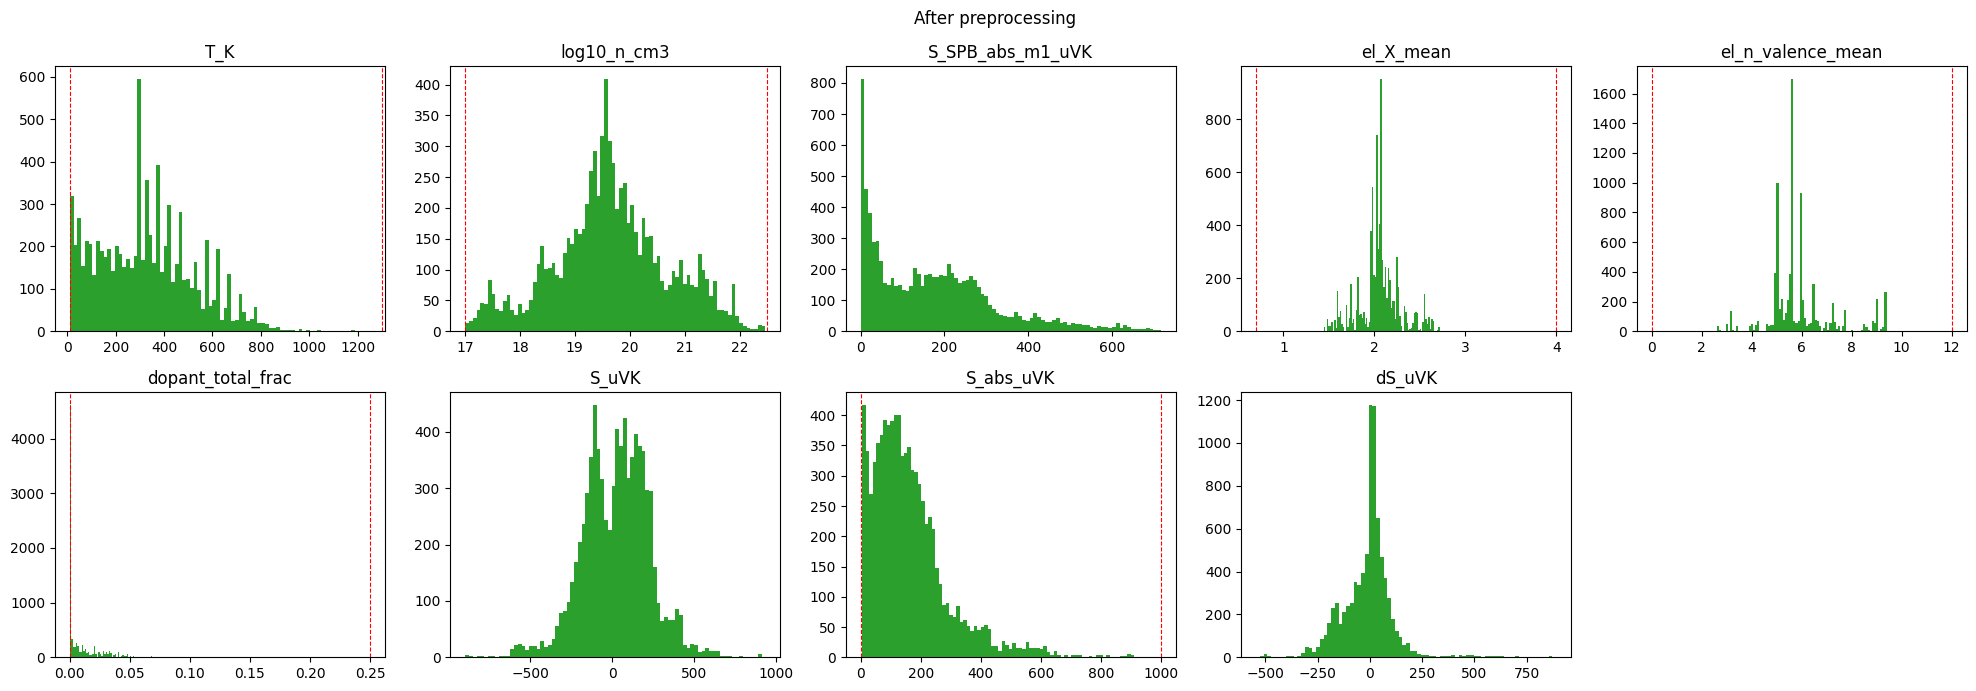

In [11]:
display(clean[cols].describe(percentiles=[.01, .5, .99]).T.round(3))
display(clean.groupby("carrier_type").agg(points=("point_id", "size"), samples=("sample_key", "nunique"), papers=("SID", "nunique")))
display(clean.groupby("comp_system").agg(points=("point_id", "size"), samples=("sample_key", "nunique"),
        papers=("SID", "nunique")).sort_values("papers", ascending=False))
hist_grid(clean, cols, "After preprocessing", color="C2")

## 7. Save

In [12]:
clean.to_csv(OUT / "seebeck_features_clean.csv", index=False)
removed.to_csv(OUT / "removed_rows.csv", index=False)
report = {"settings": {"DROP_FLAGS": DROP_FLAGS, "EXCLUDE_SIGN_CHANGING": EXCLUDE_SIGN_CHANGING, "LIMITS": LIMITS,
                       "MIN_ABS_S": MIN_ABS_S, "ROBUST_Z": ROBUST_Z, "RESIDUAL_OUTLIERS": RESIDUAL_OUTLIERS,
                       "DEDUP_ACROSS_PAPERS": DEDUP_ACROSS_PAPERS, "MAX_POINTS_PER_SAMPLE": MAX_POINTS_PER_SAMPLE},
          "counts": {**log, "raw_feature_file": len(feat), **{f"removed_{k}": v for k, v in steps.items()},
                     "clean_points": len(clean), "clean_samples": int(clean.sample_key.nunique()),
                     "clean_papers": int(clean.SID.nunique())},
          "features": FEATURES, "targets": TARGETS,
          "clean_ranges": {c: [float(clean[c].min()), float(clean[c].max())] for c in cols}}
(OUT / "preprocessing_report.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report["counts"], indent=2))

{
  "start_rows": 17590,
  "after_basic_flags": 10341,
  "after_complete_features": 10341,
  "raw_feature_file": 10341,
  "removed_sign_changing_sample": 765,
  "removed_limit_T_K": 292,
  "removed_limit_log10_n_cm3": 280,
  "removed_limit_S_abs_uVK": 74,
  "removed_limit_el_X_mean": 0,
  "removed_limit_el_n_valence_mean": 0,
  "removed_limit_dopant_total_frac": 0,
  "removed_near_zero_S": 465,
  "removed_duplicate_across_papers": 2,
  "removed_outlier_T_K": 0,
  "removed_outlier_log10_n_cm3": 0,
  "removed_outlier_S_SPB_abs_m1_uVK": 0,
  "removed_outlier_el_X_mean": 93,
  "removed_outlier_el_n_valence_mean": 12,
  "clean_points": 8358,
  "clean_samples": 982,
  "clean_papers": 263
}


In [13]:
import shutil
shutil.make_archive("seebeck_features", "zip", OUT)
try:
    from google.colab import files
    files.download("seebeck_features.zip")
except ImportError:
    print("zip at seebeck_features.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>